# 와인 품질 분류 — ESAA YB 미니 프로젝트(2)

**2조** 이승주 · 최희경 · 정경서 · 박민서

DACON [와인 품질 분류 경진대회](https://dacon.io/competitions/open/235610) 데이터로
11개 화학 성분과 와인 종류를 이용해 품질 등급(3~9점)을 예측한다. 평가 지표는 정확도다.

## 목차

1. 데이터 개요
2. 탐색적 데이터 분석
3. 전처리 — 무엇을 하고 무엇을 하지 않았는가
4. 분류 모델 세 가지
5. 앙상블과 최종 모델
6. 정리

## 이 프로젝트의 핵심 발견

**리더보드 점수의 30%는 중복 행을 외운 결과다.** test 1,000행 중 303행이 train과
성분값이 완전히 같다. 어떤 모델이든 이 303행은 100% 맞히므로, 실제 실력은
나머지 697행에서만 드러난다. 우리 최종 모델의 리더보드 0.709를 분해하면
**중복 303행 100% + 비중복 697행 58%**다.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (StratifiedKFold, StratifiedGroupKFold,
                                     cross_val_score)
from sklearn.ensemble import (ExtraTreesClassifier, RandomForestClassifier,
                              VotingClassifier)
from xgboost import XGBClassifier

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False
sns.set_style('whitegrid')

SEED = 42
train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')
sub = pd.read_csv('data/sample_submission.csv')

print('train', train.shape, '| test', test.shape)
print('결측값', train.isnull().sum().sum())
train.head(3)

train (5497, 14) | test (1000, 13)
결측값 0


,index,quality,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,type
0,0,5,5.6,0.695,0.06,6.8,0.042,9.0,84.0,0.99432,3.44,0.44,10.2,white
1,1,5,8.8,0.610,0.14,2.4,0.067,10.0,42.0,0.99690,3.19,0.59,9.5,red
2,2,5,7.9,0.210,0.39,2.0,0.057,21.0,138.0,0.99176,3.05,0.52,10.9,white


## 1. 데이터 개요

In [2]:
feat = [c for c in train.columns if c not in ('index', 'quality')]
num = [c for c in feat if c != 'type']

info = pd.DataFrame({
    '자료형': train[feat].dtypes.astype(str),
    '결측값': train[feat].isnull().sum(),
    '고유값': train[feat].nunique(),
})
info

,자료형,결측값,고유값
fixed acidity,float64,0,106
volatile acidity,float64,0,179
citric acid,float64,0,89
residual sugar,float64,0,309
chlorides,float64,0,205
free sulfur dioxide,float64,0,127
total sulfur dioxide,float64,0,271
density,float64,0,970
pH,float64,0,107
sulphates,float64,0,106


In [3]:
print('등급 분포')
dist = pd.DataFrame({
    '개수': train['quality'].value_counts().sort_index(),
    '비율(%)': (train['quality'].value_counts(normalize=True).sort_index()*100).round(2),
})
print(dist.to_string())
print()
print('종류 분포')
print(train['type'].value_counts().to_string())
print()
print('전부 6점으로 찍을 때 정확도(기준선): %.4f' % (train['quality'] == 6).mean())

등급 분포
           개수  비율(%)
quality             
3          26   0.47
4         186   3.38
5        1788  32.53
6        2416  43.95
7         924  16.81
8         152   2.77
9           5   0.09

종류 분포
type
white    4159
red      1338

전부 6점으로 찍을 때 정확도(기준선): 0.4395


## 2. 탐색적 데이터 분석

네 명이 나눠 맡았다. 승주는 변수 간 상관, 희경은 등급별 차이, 경서는 종류별 특성,
민서는 분포와 이상치를 담당했다.

### 2-1. 타깃과 종류 분포

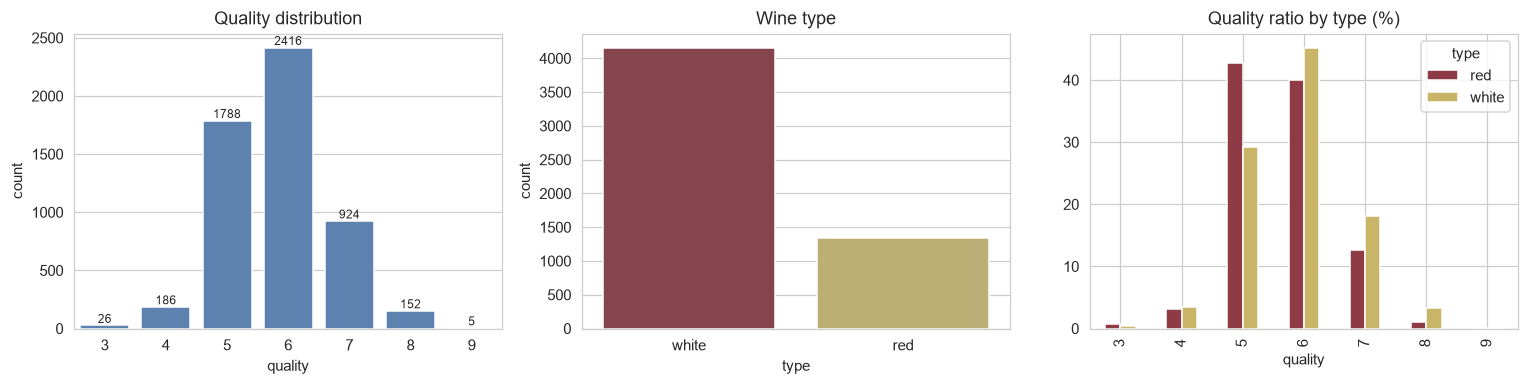

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))

sns.countplot(data=train, x='quality', ax=axes[0], color='#4f81bd')
axes[0].set_title('Quality distribution')
for p in axes[0].patches:
    axes[0].annotate('%d' % p.get_height(), (p.get_x()+p.get_width()/2, p.get_height()),
                     ha='center', va='bottom', fontsize=8)

sns.countplot(data=train, x='type', ax=axes[1],
              palette=['#8e3b46', '#c8b568'], hue='type', legend=False)
axes[1].set_title('Wine type')

ratio = pd.crosstab(train['quality'], train['type'], normalize='columns')*100
ratio.plot(kind='bar', ax=axes[2], color=['#8e3b46', '#c8b568'])
axes[2].set_title('Quality ratio by type (%)')
axes[2].set_xlabel('quality')

plt.tight_layout()
plt.show()

5·6·7점이 전체의 **93.4%**이고 3점 26개, 9점 5개로 양 끝이 극히 적다.
기준선(전부 6점)이 0.4395다.

화이트가 레드보다 3.1배 많고, 비율로 보면 화이트의 고등급 비율이 조금 높다.
평균 품질은 레드 5.638, 화이트 5.877이다.

### 2-2. 변수 간 상관 — 상관이 약하다고 빼면 안 된다

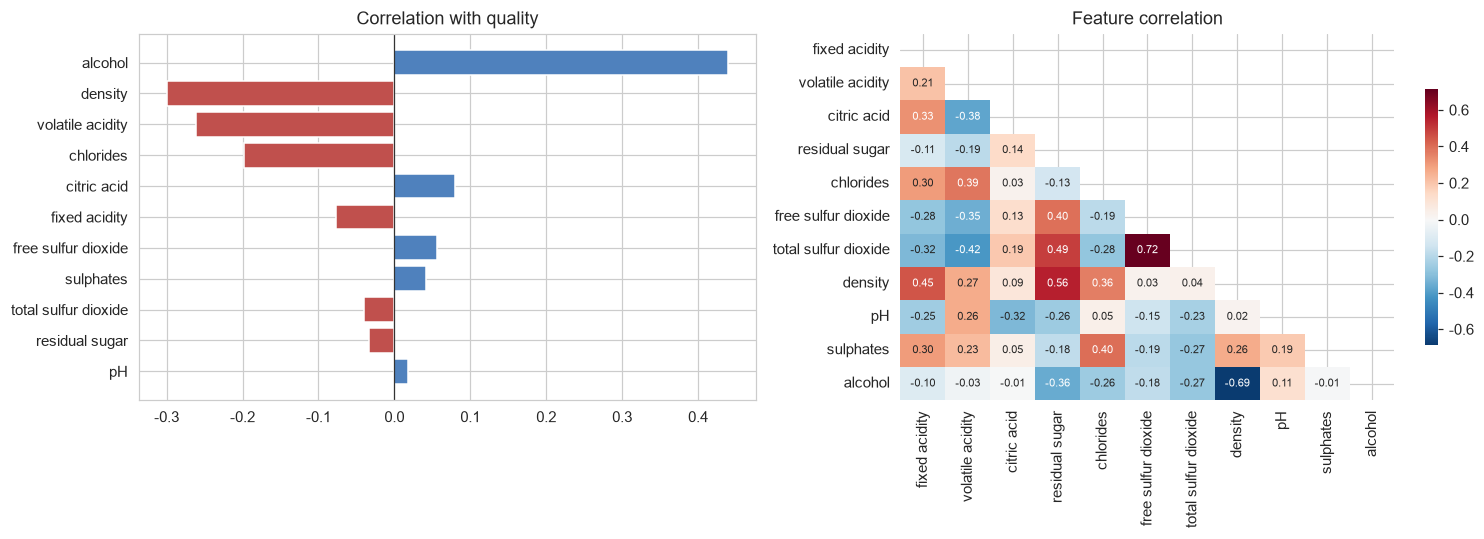

,pearson,spearman,차이
alcohol,0.440,0.444,0.004
density,-0.300,-0.321,-0.021
volatile acidity,-0.262,-0.252,0.009
chlorides,-0.198,-0.292,-0.094
citric acid,0.079,0.099,0.020
fixed acidity,-0.077,-0.097,-0.020
free sulfur dioxide,0.056,0.089,0.033
sulphates,0.042,0.035,-0.007
total sulfur dioxide,-0.040,-0.052,-0.013
residual sugar,-0.033,-0.014,0.019


In [5]:
corr_q = pd.DataFrame({
    'pearson': train[num + ['quality']].corr()['quality'].drop('quality'),
    'spearman': train[num + ['quality']].corr('spearman')['quality'].drop('quality'),
})
corr_q['차이'] = corr_q['spearman'] - corr_q['pearson']
corr_q = corr_q.reindex(corr_q['pearson'].abs().sort_values(ascending=False).index)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = corr_q.index[::-1]
axes[0].barh(order, corr_q.loc[order, 'pearson'],
             color=['#c0504d' if v < 0 else '#4f81bd' for v in corr_q.loc[order, 'pearson']])
axes[0].axvline(0, color='#333', lw=0.8)
axes[0].set_title('Correlation with quality')

C = train[num].corr()
sns.heatmap(C, mask=np.triu(np.ones_like(C, dtype=bool)), cmap='RdBu_r', center=0,
            annot=True, fmt='.2f', annot_kws={'size': 7}, ax=axes[1],
            cbar_kws={'shrink': 0.7})
axes[1].set_title('Feature correlation')
plt.tight_layout()
plt.show()

corr_q.round(3)

선형 상관이 뚜렷한 변수는 **알코올(+0.44), 밀도(−0.30), 휘발산(−0.26), 염화물(−0.20)** 네 개뿐이고
나머지 일곱 개는 |r| ≤ 0.08이다.

그래서 그 일곱 개를 빼고 돌려봤더니 **정확도가 0.6687에서 0.6427로 2.6%p 떨어졌다.**
상관이 0에 가깝다는 건 "혼자서는 설명이 안 된다"는 뜻이지 "쓸모없다"가 아니다.
→ **상관계수를 변수 선택 기준으로 쓰지 않는다.**

변수끼리 보면 **유리 SO₂ ↔ 총 SO₂가 +0.717**인데, 총량이 유리분을 포함하는 관계다.
`총 SO₂ − 유리 SO₂ = 결합 이산화황`으로 분리하면 중복이 풀린다. → 파생변수로 채택

### 2-3. 와인 종류가 상관 구조를 지배한다

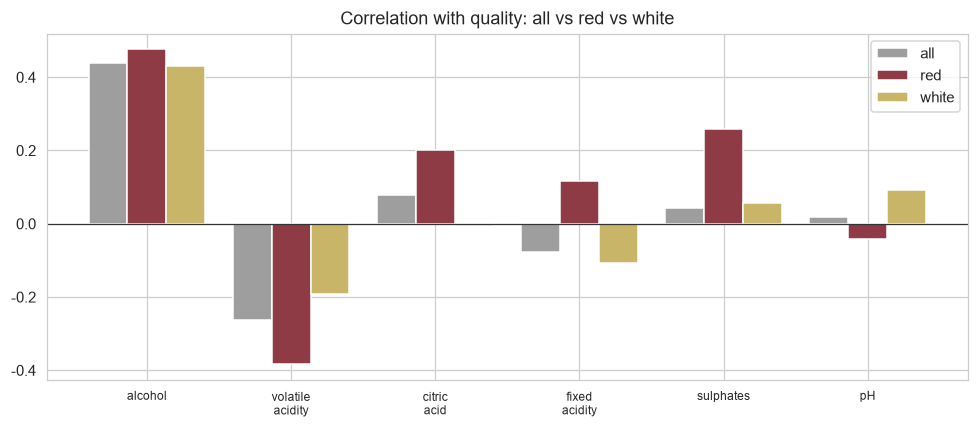

,전체,red,white
alcohol,0.440,0.476,0.430
volatile acidity,-0.262,-0.384,-0.192
citric acid,0.079,0.201,-0.005
fixed acidity,-0.077,0.116,-0.107
sulphates,0.042,0.258,0.056
pH,0.018,-0.041,0.091


In [6]:
sel = ['alcohol', 'volatile acidity', 'citric acid', 'fixed acidity', 'sulphates', 'pH']
red, white = train[train.type == 'red'], train[train.type == 'white']
tbl = pd.DataFrame({
    '전체': train[sel + ['quality']].corr()['quality'][sel],
    'red': red[sel + ['quality']].corr()['quality'][sel],
    'white': white[sel + ['quality']].corr()['quality'][sel],
})

idx = np.arange(len(sel)); w = 0.27
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(idx - w, tbl['전체'], w, label='all', color='#9e9e9e')
ax.bar(idx,     tbl['red'],  w, label='red', color='#8e3b46')
ax.bar(idx + w, tbl['white'], w, label='white', color='#c8b568')
ax.axhline(0, color='#333', lw=0.8)
ax.set_xticks(idx); ax.set_xticklabels([s.replace(' ', '\n') for s in sel], fontsize=8)
ax.set_title('Correlation with quality: all vs red vs white')
ax.legend()
plt.tight_layout(); plt.show()

tbl.round(3)

**네 변수에서 상관의 방향이 뒤집힌다.** 시트르산은 전체로는 +0.079인데 red에서 +0.201이고,
황산염은 전체 +0.042가 red에서 +0.258이다. 고정산과 pH는 아예 부호가 반대다.

등급별 EDA에서도 같은 현상이 확인됐다 — 황산염과 시트르산은 레드에서만 등급에 따라 올라간다.
세 사람이 각자 다른 방법으로 같은 결론에 도달했다.

→ **`is_white`를 반드시 피처로 넣는다.** 넣지 않으면 모델이 red의 신호와 white의 신호를
구분하지 못하고 평균을 내버린다.

### 2-4. 등급별 차이와 분포

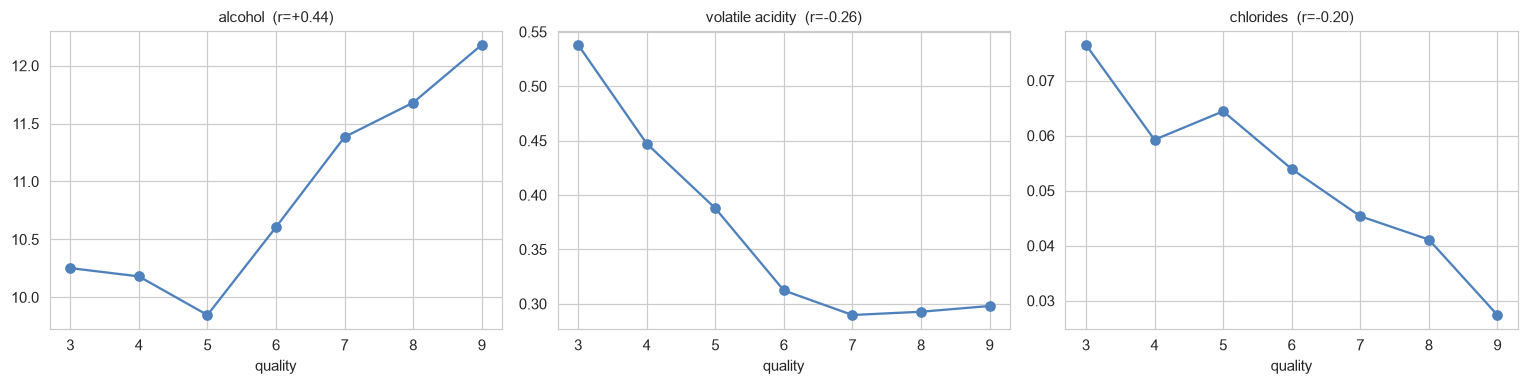

    chlorides  sulphates  fixed acidity  residual sugar  volatile acidity  free sulfur dioxide  density  alcohol  citric acid    pH  total sulfur dioxide
왜도       5.19       1.92           1.71             1.5               1.5                 1.31      0.6     0.55         0.49  0.39                   0.0


In [7]:
by_q = train.groupby('quality')[num].mean()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col in zip(axes, ['alcohol', 'volatile acidity', 'chlorides']):
    ax.plot(by_q.index, by_q[col], 'o-', color='#4f81bd')
    ax.set_title('%s  (r=%+.2f)' % (col, train[col].corr(train['quality'])), fontsize=10)
    ax.set_xlabel('quality')
plt.tight_layout(); plt.show()

skew = pd.DataFrame({'왜도': train[num].skew().round(2)}).sort_values('왜도', ascending=False)
print(skew.T.to_string())

**알코올은 직선이 아니라 U자다.** 5점에서 9.85로 최저이고 3점은 10.15로 오히려 높다.
"알코올이 높으면 좋다"가 아니라 "5점 근처가 가장 낮고 거기서 멀어질수록 높다"는 모양이라,
상관계수 +0.44는 관계를 과소평가하고 있다.

왜도를 보면 **염화물 5.19**로 가장 치우쳐 있고 황산염 1.92, 고정산 1.71이 뒤를 잇는다.
보통은 로그 변환 대상인데, 3절에서 실제로 재보고 판단한다.

### 2-5. 중복 행 — 이 프로젝트의 핵심 발견

In [8]:
uniq = train[feat].drop_duplicates()
dup_rows = train[feat].duplicated(keep=False).sum()
g = train.groupby(feat, sort=False)['quality'].nunique()

print('train 행 수               : %d' % len(train))
print('성분 기준 고유한 와인      : %d' % len(uniq))
print('중복을 하나만 남길 때 제외 : %d행' % train[feat].duplicated().sum())
print('중복 그룹에 속한 행        : %d행 (%.1f%%)' % (dup_rows, 100*dup_rows/len(train)))
print('중복인데 등급이 엇갈리는 조합: %d개' % int((g > 1).sum()))
print()

lookup = train.drop_duplicates(subset=feat).set_index(feat)['quality']
key = pd.MultiIndex.from_frame(test[feat])
dup_test = np.asarray(key.isin(lookup.index))
print('test 1,000행 중 train과 성분이 완전히 같은 행: %d행 (%.1f%%)'
      % (dup_test.sum(), 100*dup_test.mean()))

train 행 수               : 5497
성분 기준 고유한 와인      : 4639
중복을 하나만 남길 때 제외 : 858행
중복 그룹에 속한 행        : 1603행 (29.2%)
중복인데 등급이 엇갈리는 조합: 0개

test 1,000행 중 train과 성분이 완전히 같은 행: 303행 (30.3%)


성분 11개와 종류가 **완전히 같은 행**이 train에 858개 있다. 그리고 그런 행들은
**등급도 예외 없이 같다**(엇갈리는 조합 0개).

더 중요한 건 **test의 30.3%도 train과 같다**는 점이다. 이 구조가 평가에 두 가지 영향을 준다.

**① 교차검증 점수가 부풀려진다.** 무작위로 폴드를 나누면 같은 와인이 학습과 검증에
동시에 들어가 모델이 외운 답을 그대로 맞힌다.

**② 그래도 중복을 지우면 안 된다.** test의 30%가 겹치므로 외우는 것이 실제로 점수가 된다.

In [9]:
def make_x(df):
    X = df.drop(columns=[c for c in ('index', 'quality') if c in df.columns])
    X['is_white'] = (X['type'] == 'white').astype(int)
    X = X.drop(columns=['type'])
    X['bound_so2'] = X['total sulfur dioxide'] - X['free sulfur dioxide']
    return X

X, y = make_x(train), train['quality']
X_test = make_x(test)
groups = train.groupby(feat, sort=False).ngroup()

cv_plain = StratifiedKFold(5, shuffle=True, random_state=SEED)
cv_group = StratifiedGroupKFold(5, shuffle=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

a = cross_val_score(rf, X, y, cv=cv_plain, n_jobs=1)
b = cross_val_score(rf, X, y, cv=cv_group, groups=groups, n_jobs=1)

ded = train.drop_duplicates(subset=feat)
Xd, yd = make_x(ded), ded['quality']
cc = cross_val_score(rf, Xd, yd, cv=cv_plain, n_jobs=1)

print('(a) 무작위 분할  StratifiedKFold      %.4f (±%.4f)' % (a.mean(), a.std()))
print('(b) 같은 와인을 한 폴드로 묶으면      %.4f (±%.4f)' % (b.mean(), b.std()))
print('(c) 중복을 지우고 학습 (%d행)       %.4f (±%.4f)' % (len(ded), cc.mean(), cc.std()))
print()
print('(a) - (b) = %+.4f  <- 중복 겹침에서 온 몫' % (a.mean() - b.mean()))

(a) 무작위 분할  StratifiedKFold      0.6735 (±0.0077)
(b) 같은 와인을 한 폴드로 묶으면      0.5750 (±0.0084)
(c) 중복을 지우고 학습 (4639행)       0.5753 (±0.0123)

(a) - (b) = +0.0984  <- 중복 겹침에서 온 몫


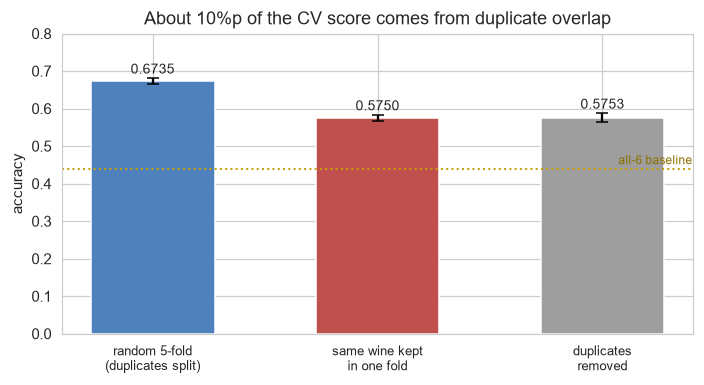

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
vals = [a.mean(), b.mean(), cc.mean()]
errs = [a.std(), b.std(), cc.std()]
names = ['random 5-fold\n(duplicates split)', 'same wine kept\nin one fold', 'duplicates\nremoved']
ax.bar(np.arange(3), vals, yerr=errs, capsize=4,
       color=['#4f81bd', '#c0504d', '#9e9e9e'], width=0.55)
for i, v in enumerate(vals):
    ax.text(i, v + errs[i] + 0.012, '%.4f' % v, ha='center', fontsize=9)
ax.axhline(0.4395, color='#c8a000', ls=':', lw=1.3)
ax.text(2.4, 0.4395+0.012, 'all-6 baseline', ha='right', fontsize=8, color='#8a7000')
ax.set_ylim(0, 0.8); ax.set_ylabel('accuracy')
ax.set_xticks(np.arange(3)); ax.set_xticklabels(names, fontsize=8.5)
ax.set_title('About 10%p of the CV score comes from duplicate overlap')
plt.tight_layout(); plt.show()

**약 10%p 차이다.** 두 방식의 폴드 크기와 등급 분포는 사실상 같고, 달라지는 것은
검증 폴드에 학습 폴드와 같은 와인이 있느냐(평균 24.1%)와 없느냐(0%)뿐이다.

중복을 지우면 0.58 아래로 떨어진다. **지우지 않고, 대신 두 점수를 구분해서 기록한다.**

- **일반 교차검증** — 실험 간 비교의 공통 기준. test도 30% 겹치므로 리더보드 대리값
- **그룹 교차검증** — 처음 보는 와인에 대한 실제 실력

## 3. 전처리 — 무엇을 하고 무엇을 하지 않았는가

전처리는 **네 줄이 전부**다. 나머지는 전부 실험해보고 **효과가 없거나 손해여서 하지 않았다.**

```python
X = df.drop(columns=['index', 'quality'])
X['is_white'] = (X['type'] == 'white').astype(int)
X = X.drop(columns=['type'])
X['bound_so2'] = X['total sulfur dioxide'] - X['free sulfur dioxide']
```

### 3-1. 불균형 처리 — 하지 않는다

3점 26개, 9점 5개로 심하게 치우쳐 있다. 네 모델 × 세 처리 = 11개 조합을 비교했다.

| 모델 | 미적용 | RandomOver | SMOTE | class_weight |
|---|---|---|---|---|
| 엑스트라 트리 | **0.6798** | −0.0044 | −0.0306 | −0.0040 |
| 랜덤포레스트 | **0.6735** | −0.0033 | −0.0346 | −0.0391 |
| XGBoost | **0.6540** | −0.0113 | −0.0171 | 지원 안 함 |
| LightGBM | 0.6513 | +0.0022 | −0.0095 | −0.0047 |

**미적용을 이긴 것은 LightGBM의 +0.0022 하나뿐**이고 표준편차(±0.011) 안이다.

macro F1과 balanced accuracy는 실제로 좋아진다. 불균형 처리는 제 할 일을 하고 있다.
다만 그 지표들은 5병짜리 9점과 2,416병짜리 6점을 똑같이 세는데,
**대회 지표는 정확도**라 5·6·7점(93.4%)을 맞히는 것이 전부다.

> 평가 산식이 정확도라서 하지 않는 것이지, 불균형 처리가 나쁜 기법이라서가 아니다.

리샘플링은 반드시 폴드 안에서 해야 한다. 분할 전에 SMOTE를 적용하면
0.6353이 **0.8929**로 뛰는데, 합성 샘플이 검증셋으로 새어 들어간 가짜 점수다.

### 3-2. 로그 변환과 이상치 — 하지 않는다

염화물의 왜도가 5.19로 가장 크다. 로그 변환과 IQR 캡핑을 10가지 조합으로 비교했다.

| 처리 | 랜덤포레스트 | 엑스트라 트리 |
|---|---|---|
| **원본** | **0.6735** | **0.6798** |
| log 3개 | +0.0024 | −0.0040 |
| log 6개 전부 | +0.0009 | −0.0045 |
| 캡핑 3개 | −0.0016 | +0.0011 |
| 캡핑 6개 | −0.0049 | −0.0035 |

한쪽에서 오르면 다른 쪽에서 떨어진다. **트리는 값의 순서만 보는데 로그는 순서를
바꾸지 않으므로** 같은 트리가 나온다. 참고로 로지스틱 회귀에서는 log 변환이 +0.0033으로
일관되게 올랐다. 진단은 맞았지만 처방이 트리 모델에 걸리지 않았다.

이상치도 삭제하지 않는다. 와인의 극단값은 오류가 아니라 특정 품종의 특성일 가능성이 크고,
지우면 희귀 등급의 정보가 사라진다.

### 3-3. 파생변수 — 결합 이산화황만 채택

| 피처 구성 | ET | RF | XGB | LGBM |
|---|---|---|---|---|
| 원본 + `is_white` | 0.6765 | 0.6687 | 0.6505 | 0.6493 |
| **+ 결합 SO₂** | **0.6798** | **0.6735** | **0.6540** | **0.6513** |

네 모델 모두 올랐다. 다만 각각은 +0.002~+0.005로 표준편차 안이라,
근거는 "네 번 모두 같은 방향"이라는 일관성이다.

다른 파생변수는 전부 효과가 없었다. `total_acidity`는 고정산과 상관이 **0.993**,
`pH × density`는 pH와 **0.998**이라 사실상 같은 변수를 한 번 더 넣는 것이었다.
`alcohol/density`, `잔당/알코올` 같은 비율 변수도 결합 SO₂ 하나만 넣은 것과 차이가 없었다.

`density`는 VIF 15.5로 중복이지만 **네 모델 중 셋에서 빼면 떨어져서** 유지했다.
VIF가 문제가 되는 건 선형 모델이고, 트리는 변수가 겹쳐도 성능이 나빠지지 않는다.

## 4. 분류 모델 세 가지

엑스트라 트리, 랜덤포레스트, XGBoost를 각각 한 명씩 맡아 튜닝했다.
모두 같은 전처리와 같은 검증 설정에서 출발했다.

In [11]:
def evaluate(model, name, shift=False):
    tgt = y - 3 if shift else y
    s = cross_val_score(model, X, tgt, cv=cv_plain, n_jobs=1)
    g = cross_val_score(model, X, tgt, cv=cv_group, groups=groups, n_jobs=1)
    print('%-16s 일반 CV %.4f (±%.4f)   그룹 CV %.4f (±%.4f)'
          % (name, s.mean(), s.std(), g.mean(), g.std()))
    print('%-16s 폴드별 %s' % ('', np.round(s, 4).tolist()))
    return s.mean(), g.mean()


res = {}
res['엑스트라 트리'] = evaluate(
    ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=-1), '엑스트라 트리')
res['랜덤포레스트'] = evaluate(
    RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1), '랜덤포레스트')
res['XGBoost'] = evaluate(
    XGBClassifier(n_estimators=500, learning_rate=0.03, max_depth=8,
                  min_child_weight=1, subsample=0.8, colsample_bytree=0.8,
                  objective='multi:softprob', eval_metric='mlogloss',
                  random_state=SEED, n_jobs=-1), 'XGBoost', shift=True)

엑스트라 트리          일반 CV 0.6798 (±0.0112)   그룹 CV 0.5739 (±0.0098)
                 폴드별 [0.6964, 0.6836, 0.6779, 0.6797, 0.6615]


랜덤포레스트           일반 CV 0.6735 (±0.0077)   그룹 CV 0.5750 (±0.0084)
                 폴드별 [0.6836, 0.6773, 0.667, 0.677, 0.6624]


XGBoost          일반 CV 0.6653 (±0.0110)   그룹 CV 0.5594 (±0.0139)
                 폴드별 [0.6682, 0.6709, 0.6642, 0.6779, 0.6451]


### 튜닝에서 배운 것

**엑스트라 트리와 랜덤포레스트는 기본 설정이 최적이었다.** 10개·30개 조합을 탐색했지만
오차 범위를 넘는 개선이 없었다. 한 가지 함정이 있었는데, `max_features` 탐색 범위를
0.7~1.0으로 잡으면 **기본값 `sqrt`(피처 13개 기준 0.277)가 탐색 공간 밖**이라
기본값을 이길 수 없다. 실제로 값이 커질수록 점수가 떨어진다.

**XGBoost만 튜닝 효과가 있었다.** 0.6387에서 0.6665로 올랐는데, 그 원인이 중요하다.

In [12]:
rows = []
for d in (5, 6, 7, 8):
    m = XGBClassifier(n_estimators=500, learning_rate=0.03, max_depth=d,
                      min_child_weight=1, subsample=0.8, colsample_bytree=0.8,
                      objective='multi:softprob', eval_metric='mlogloss',
                      random_state=SEED, n_jobs=-1)
    s = cross_val_score(m, X, y - 3, cv=cv_plain, n_jobs=1)
    m.fit(X, y - 3)
    pred = m.predict(X_test) + 3
    hit = (pred[dup_test] == lookup.reindex(key[dup_test]).values).mean()
    rows.append({'max_depth': d, '일반 CV': round(s.mean(), 4),
                 'test 중복 303행 정답률': '%.1f%%' % (100*hit)})
pd.DataFrame(rows)

,max_depth,일반 CV,test 중복 303행 정답률
0,5,0.6322,85.8%
1,6,0.6482,95.4%
2,7,0.6578,98.0%
3,8,0.6653,100.0%


**깊이를 늘릴수록 좋아진 이유는 중복 행을 외우는 능력이 올라갔기 때문이다.**
깊이 8에서 중복 303행을 100% 맞히게 되고, 그 뒤로는 더 깊게 해도 나아지지 않는다.

엑스트라 트리와 랜덤포레스트는 **기본값이 깊이 무제한이라 처음부터 100%**였다.
그래서 두 모델은 튜닝해도 오르지 않았던 것이다. 이미 외울 수 있는 것을 다 외우고 있었다.

## 5. 앙상블과 최종 모델

In [13]:
vote = VotingClassifier(
    estimators=[
        ('et', ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
        ('rf', RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
        ('xgb', XGBClassifier(n_estimators=500, learning_rate=0.03, max_depth=8,
                              min_child_weight=1, subsample=0.8, colsample_bytree=0.8,
                              objective='multi:softprob', eval_metric='mlogloss',
                              random_state=SEED, n_jobs=-1)),
    ], voting='soft', weights=[2, 2, 1])

res['소프트 보팅 2:2:1'] = evaluate(vote, '소프트 보팅 2:2:1', shift=True)

summary = pd.DataFrame(res, index=['일반 CV', '그룹 CV']).T
summary['예상 리더보드'] = ((303 + 697*summary['그룹 CV'])/1000).round(4)
summary.round(4)

소프트 보팅 2:2:1     일반 CV 0.6818 (±0.0103)   그룹 CV 0.5765 (±0.0098)
                 폴드별 [0.6891, 0.6891, 0.6843, 0.6852, 0.6615]


,일반 CV,그룹 CV,예상 리더보드
엑스트라 트리,0.6798,0.5739,0.7030
랜덤포레스트,0.6735,0.5750,0.7038
XGBoost,0.6653,0.5594,0.6929
소프트 보팅 2:2:1,0.6818,0.5765,0.7048


세 모델의 예측은 서로 꽤 다르다. 엑스트라 트리를 기준으로 랜덤포레스트가 73행,
XGBoost가 104행 다르게 예측한다. **XGBoost는 단독 성능이 가장 낮지만 가장 다르게
예측해서** 섞었을 때 도움이 된다. 가중치를 2:2:1로 둔 것은 성능 차이를 반영한 것이다.

### 리더보드 점수는 그룹 CV로 예측할 수 있다

$$\text{리더보드} = \frac{303 \times 1.0 + 697 \times \text{그룹 CV}}{1000}$$

| 모델 | 그룹 CV | 예측 | 실제 |
|---|---|---|---|
| 소프트 보팅 2:2:1 | 0.5765 | 0.705 | **0.705** |
| 상위 ET/RF 6개 평균 | 0.5781 | 0.708 | 0.705 |
| RF + ET + 스태킹 | 0.5829 | 0.709 | **0.709** |

중복 303행은 어떤 모델이든 100% 맞히므로, **차이는 나머지 697행에서만 난다.**
실제로 세 모델의 제출 파일을 비교하면 중복 303행은 완전히 일치하고
34~52행의 차이가 전부 비중복 697행에서 발생한다.

### 최종 모델 — 랜덤포레스트 + 엑스트라 트리 + 스태킹

리더보드 **0.709**로 가장 높았다. 2단 구조다.

```
[1단] RF + ET + CatBoost 확률 -> 로지스틱 회귀로 스태킹
      (메타 학습용 확률은 같은 와인을 한 폴드로 묶은 3-Fold OOF로 생성)
[2단] RF 확률, ET 확률(bound_so2 제외 + MinMax), 1단 스태킹 확률을 같은 비중으로 평균
[보정] test에서 train과 성분이 같은 행은 train의 등급으로 맞춤
```

구조와 하이퍼파라미터는
[25-2 YB 1조 미니 프로젝트 Method 1](https://github.com/gravity102424/ESAA/blob/main/ESAA_YB_MiniProject(2).ipynb)을
참고했다.

In [14]:
# 최종 제출 파일 생성 (소프트 보팅 2:2:1 기준 — 재현 가능한 단일 파이프라인)
vote.fit(X, y - 3)
pred = (vote.predict(X_test) + 3).astype(int)

# 중복 보정: test에서 train과 성분이 같은 행은 train 등급으로
pred_before = pred.copy()
pred[dup_test] = lookup.reindex(key[dup_test]).values.astype(int)
print('중복 보정으로 바뀐 행: %d개' % int((pred != pred_before).sum()))
print('중복 303행 정답률: %.1f%%' % (100*(pred_before[dup_test] ==
                                    lookup.reindex(key[dup_test]).values).mean()))

submission = sub.copy()
submission['quality'] = pred
submission.to_csv('submission.csv', index=False)
print()
print(submission['quality'].value_counts().sort_index().to_string())
submission.head()

중복 보정으로 바뀐 행: 0개
중복 303행 정답률: 100.0%



quality
4      6
5    351
6    508
7    123
8     12


,index,quality
0,0,5
1,1,6
2,2,6
3,3,5
4,4,6


## 6. 정리

### 결과

| 모델 | 일반 CV | 그룹 CV | 리더보드 |
|---|---|---|---|
| 엑스트라 트리 | 0.6798 | 0.5739 | 0.697 |
| 랜덤포레스트 | 0.6735 | 0.5750 | 0.698 |
| XGBoost | 0.6653 | 0.5594 | 0.695 |
| 소프트 보팅 2:2:1 | 0.6818 | 0.5765 | 0.705 |
| **RF + ET + 스태킹** | — | 0.5829 | **0.709** |
| *기준선 (전부 6점)* | *0.4395* | | |

### 배운 것

**전처리는 대부분 "해보고 안 하기로 한 것"이다.** 불균형 처리 11조합, 로그 변환·캡핑
10조합, 파생변수 7종, 변수 제거를 모두 시험했지만 안정적으로 개선된 것은
결합 이산화황 하나뿐이었다. 근거 없이 붙이지 않은 것이 결과적으로 맞았다.

**지표가 방법을 결정한다.** 불균형 처리는 macro F1을 올리지만 정확도는 떨어뜨린다.
대회 지표가 정확도라서 하지 않은 것이지, 기법이 나빠서가 아니다.

**검증 설계가 결과를 바꾼다.** 설정만 바꿔도 점수가 0.007 움직이는데
파생변수로 얻으려던 것이 0.003~0.005였다. 높게 나오는 설정이 아니라
덜 흔들리는 설정을 골라야 한다.

**가장 중요한 것은 점수의 구조를 아는 것이다.** 리더보드 0.709는
중복 303행을 100% 맞힌 것과 나머지 697행을 58% 맞힌 것의 합이다.
전자는 어떤 모델이든 같으므로, 모델의 차이는 후자에서만 드러난다.

### 한계

**처음 보는 와인에 대한 정확도는 0.58 근처가 한계였다.** 모델 12종, 하이퍼파라미터
32조합, 결합 방식 5종, 인접 등급 전용 분류기까지 시험했지만 모두 +0.002 안에 머물렀다.

이유는 라벨 자체에 있는 것으로 보인다. 32개 모델이 **모두 틀리는 행이 27.7%**이고,
오답의 **89.6%가 1점 차이**다. 5점과 6점을 가르는 경계는 관능 평가자도
일관되게 구분하기 어려운 영역이다.